# Phase F — Headline figures
### *Trustworthiness Under Compression* — the four figures that carry the paper

Assembles publication-quality figures from the CSVs produced in Phases B–E. No model loading — pure plotting, so it's fast and re-runnable. Saves 300-dpi PNG + vector PDF to `results/figures/`.

**The four headline figures:**
1. **Trust-vs-compression gradient** — accuracy survives, calibration and faithfulness degrade with compression aggressiveness; faithfulness null band shaded.
2. **Convergence heatmap (the killer figure)** — per-class calibration gap AND faithfulness drift under prune80; the rare classes collapse in *both*.
3. **Cross-dataset transfer** — the same per-class pattern on CICIoT2023 *and* TON_IoT.
4. **The remedy** — temperature scaling recovers calibration (ECE raw vs temp).

Gracefully skips any figure whose CSV isn't present yet.

## 0. Setup + load all CSVs

In [1]:
import os, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
                 'figure.dpi':120,'savefig.bbox':'tight'})
ROOT='/content/drive/MyDrive/Trustworthiness_IoT'
if not os.path.isdir(ROOT):
    from google.colab import drive; drive.mount('/content/drive')
RES=f'{ROOT}/results'; TRES=f'{ROOT}/ton_iot/results'; FIG=f'{RES}/figures'; os.makedirs(FIG,exist_ok=True)

def load(path):
    return pd.read_csv(path) if os.path.exists(path) else None
def parse_mean(s):
    m=re.match(r'^\s*(-?\d+\.?\d*)',str(s)); return float(m.group(1)) if m else np.nan

# CICIoT2023
cal   = load(f'{RES}/calibration_test.csv')
calpc = load(f'{RES}/calibration_perclass.csv')
dep   = load(f'{RES}/deployability_proxy.csv')
fag   = load(f'{RES}/faithfulness_agreement_v2.csv')
fpc   = load(f'{RES}/faithfulness_perclass_spearman_v2.csv')
# TON_IoT
tcal  = load(f'{TRES}/calibration.csv'); tcalpc=load(f'{TRES}/calibration_perclass.csv')
tfag  = load(f'{TRES}/faithfulness_agreement.csv'); tfpc=load(f'{TRES}/faithfulness_perclass.csv')
# Phase E
mig   = load(f'{RES}/feature_family_migration.csv')
ORDER=['M0','M0_anchor','M2_prune50','M2_prune80','M3_distilled','M1_int8','M1_float16']
print('loaded:', {k:(v is not None) for k,v in
      dict(cal=cal,calpc=calpc,dep=dep,fag=fag,fpc=fpc,tcal=tcal,tfpc=tfpc,mig=mig).items()})

Mounted at /content/drive
loaded: {'cal': True, 'calpc': True, 'dep': True, 'fag': True, 'fpc': True, 'tcal': True, 'tfpc': True, 'mig': False}


## Figure 1 — Trust degrades with compression (accuracy survives)

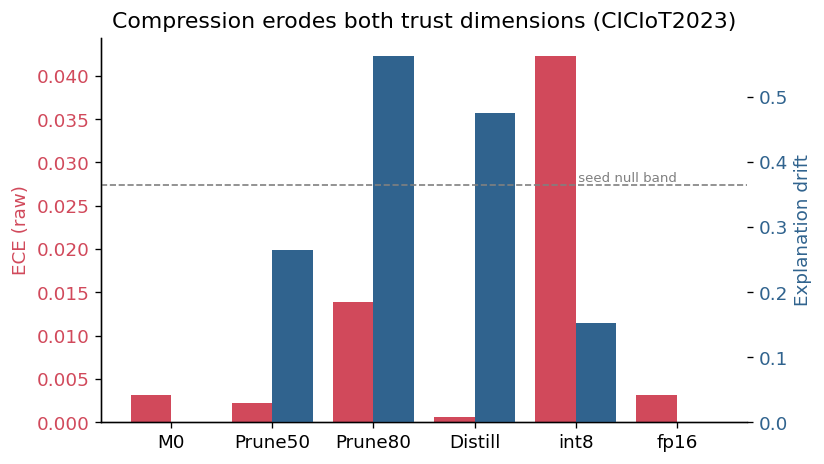

saved fig1


In [2]:
# Order variants by compression aggressiveness; plot ECE (calibration) and 1-Spearman (faithfulness drift)
if cal is not None and fag is not None:
    label_map={'M0':'M0','M0_anchor':'M0','M2_prune50':'Prune50','M2_prune80':'Prune80',
               'M3_distilled':'Distill','M1_int8':'int8','M1_float16':'fp16'}
    seq=['M0','M2_prune50','M2_prune80','M3_distilled','M1_int8','M1_float16']
    cal_i=cal.set_index('model')
    fag_i=fag.set_index('comparison')
    null_lo=fag_i.loc['NULL_seed','CI_low'] if 'NULL_seed' in fag_i.index else np.nan
    xs=[]; ece=[]; drift=[]
    for m in seq:
        key='M0_anchor' if (m=='M0' and 'M0_anchor' in cal_i.index) else m
        if key in cal_i.index:
            xs.append(label_map.get(m,m)); ece.append(cal_i.loc[key,'ECE_raw'])
            drift.append(1-fag_i.loc[m,'spearman'] if m in fag_i.index else 0.0)
    fig,ax1=plt.subplots(figsize=(7,4))
    x=np.arange(len(xs))
    b1=ax1.bar(x-0.2,ece,0.4,label='Calibration error (ECE)',color='#d1495b')
    ax1.set_ylabel('ECE (raw)',color='#d1495b'); ax1.tick_params(axis='y',labelcolor='#d1495b')
    ax2=ax1.twinx(); ax2.spines['top'].set_visible(False)
    b2=ax2.bar(x+0.2,drift,0.4,label='Explanation drift (1−Spearman)',color='#30638e')
    ax2.set_ylabel('Explanation drift',color='#30638e'); ax2.tick_params(axis='y',labelcolor='#30638e')
    if not np.isnan(null_lo):
        ax2.axhline(1-null_lo,ls='--',color='gray',lw=1)
        ax2.text(len(xs)-1,1-null_lo,' seed null band',va='bottom',ha='right',fontsize=8,color='gray')
    ax1.set_xticks(x); ax1.set_xticklabels(xs); ax1.set_title('Compression erodes both trust dimensions (CICIoT2023)')
    fig.tight_layout(); fig.savefig(f'{FIG}/fig1_trust_gradient.png',dpi=300); fig.savefig(f'{FIG}/fig1_trust_gradient.pdf')
    plt.show(); print('saved fig1')
else: print('skip fig1 (need calibration_test + faithfulness_agreement)')

## Figure 2 — Convergence heatmap (the killer figure)

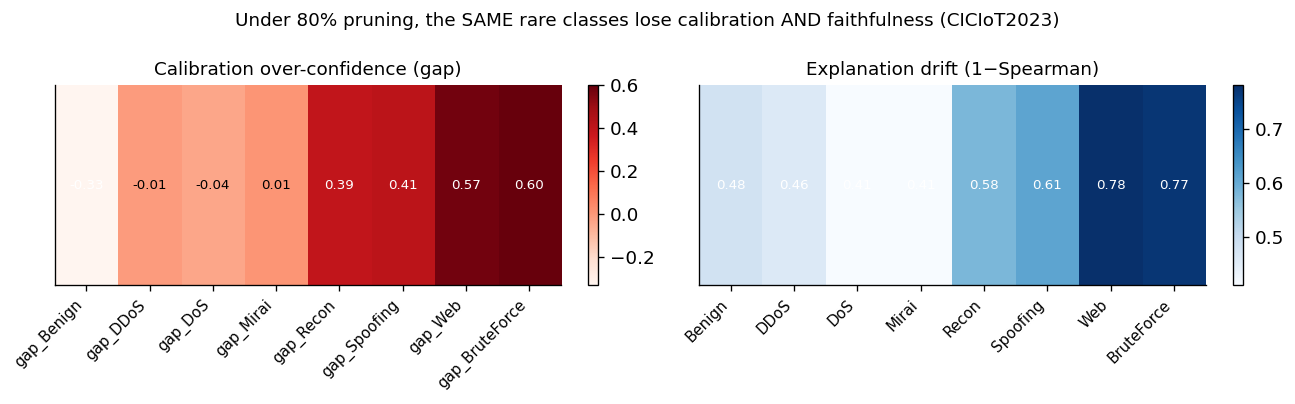

saved fig2


In [3]:
# Per-class calibration gap (prune80) and faithfulness drift (1-Spearman, prune80), side by side
if calpc is not None and fpc is not None:
    PRUNE='M2_prune80'
    cap=calpc.set_index('model')
    classes=[c for c in cap.columns if c!='model']
    cal_row=cap.loc[PRUNE,classes].astype(float).values if PRUNE in cap.index else None
    fp=fpc.set_index('model')
    fcols=[c for c in fp.columns if c!='model']
    fai_row=np.array([1-parse_mean(fp.loc[PRUNE,c]) for c in fcols]) if PRUNE in fp.index else None
    if cal_row is not None and fai_row is not None:
        fig,axes=plt.subplots(1,2,figsize=(11,3.4))
        for ax,(title,vals,labs,cmap) in zip(axes,
            [('Calibration over-confidence (gap)',cal_row,classes,'Reds'),
             ('Explanation drift (1−Spearman)',fai_row,fcols,'Blues')]):
            im=ax.imshow(vals.reshape(1,-1),cmap=cmap,aspect='auto')
            ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs,rotation=45,ha='right',fontsize=9)
            ax.set_yticks([]); ax.set_title(title,fontsize=11)
            for j,v in enumerate(vals): ax.text(j,0,f'{v:.2f}',ha='center',va='center',fontsize=8,
                                                color='white' if abs(v)>np.nanmax(np.abs(vals))*0.5 else 'black')
            fig.colorbar(im,ax=ax,fraction=0.025)
        fig.suptitle('Under 80% pruning, the SAME rare classes lose calibration AND faithfulness (CICIoT2023)',fontsize=11)
        fig.tight_layout(); fig.savefig(f'{FIG}/fig2_convergence.png',dpi=300); fig.savefig(f'{FIG}/fig2_convergence.pdf')
        plt.show(); print('saved fig2')
    else: print('skip fig2 (prune80 row missing)')
else: print('skip fig2 (need calibration_perclass + faithfulness_perclass)')

## Figure 3 — Cross-dataset transfer (CICIoT2023 vs TON_IoT)

/tmp/ipykernel_40433/1978685919.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.array(lab)[order],rotation=45,ha='right',fontsize=9)
/tmp/ipykernel_40433/1978685919.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.array(lab)[order],rotation=45,ha='right',fontsize=9)


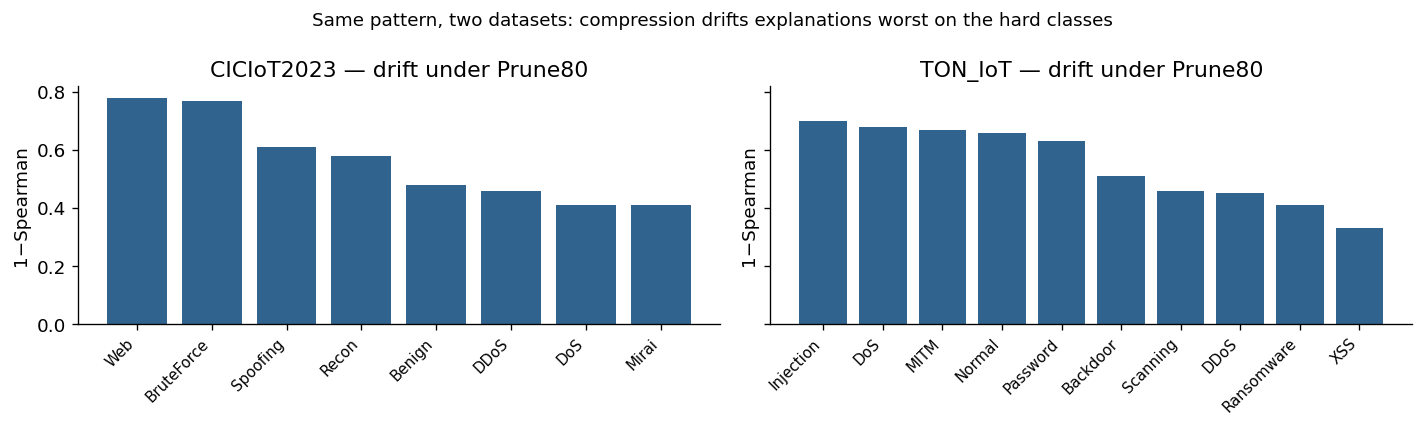

saved fig3


In [4]:
# Per-class faithfulness drift under prune80 on BOTH datasets
def perclass_drift(fpc_df, model='M2_prune80'):
    if fpc_df is None: return None,None
    fp=fpc_df.set_index('model'); cols=[c for c in fp.columns if c!='model']
    if model not in fp.index: return None,None
    return cols,[1-parse_mean(fp.loc[model,c]) for c in cols]
c_lab,c_val=perclass_drift(fpc); t_lab,t_val=perclass_drift(tfpc)
if c_val is not None and t_val is not None:
    fig,axes=plt.subplots(1,2,figsize=(12,3.6),sharey=True)
    for ax,(name,lab,val) in zip(axes,[('CICIoT2023',c_lab,c_val),('TON_IoT',t_lab,t_val)]):
        order=np.argsort(val)[::-1]
        ax.bar(np.array(lab)[order],np.array(val)[order],color='#30638e')
        ax.set_xticklabels(np.array(lab)[order],rotation=45,ha='right',fontsize=9)
        ax.set_title(f'{name} — drift under Prune80'); ax.set_ylabel('1−Spearman')
    fig.suptitle('Same pattern, two datasets: compression drifts explanations worst on the hard classes',fontsize=11)
    fig.tight_layout(); fig.savefig(f'{FIG}/fig3_transfer.png',dpi=300); fig.savefig(f'{FIG}/fig3_transfer.pdf')
    plt.show(); print('saved fig3')
else: print('skip fig3 (need both faithfulness_perclass CSVs)')

## Figure 4 — The remedy (temperature scaling recovers calibration)

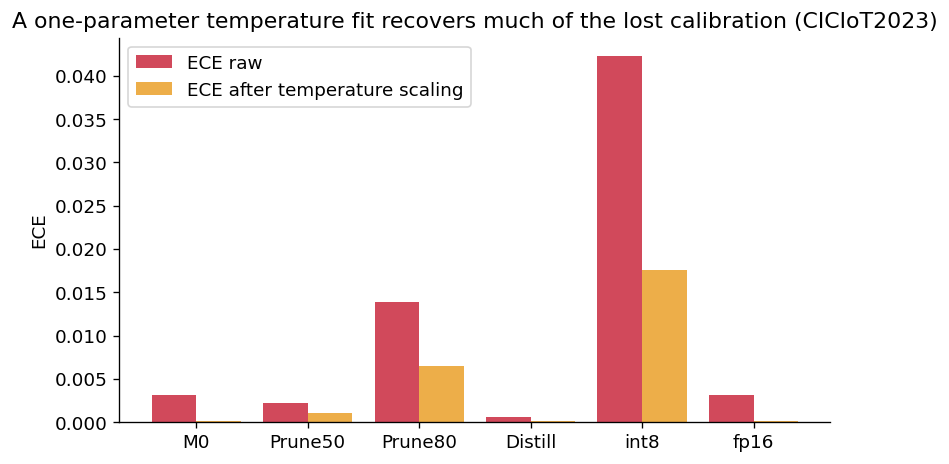

saved fig4


In [5]:
if cal is not None and 'ECE_temp' in cal.columns:
    seq=['M0','M0_anchor','M2_prune50','M2_prune80','M3_distilled','M1_int8','M1_float16']
    ci=cal.set_index('model'); rows=[m for m in seq if m in ci.index]
    labs=[{'M0_anchor':'M0','M0':'M0','M2_prune50':'Prune50','M2_prune80':'Prune80',
           'M3_distilled':'Distill','M1_int8':'int8','M1_float16':'fp16'}.get(m,m) for m in rows]
    raw=[ci.loc[m,'ECE_raw'] for m in rows]; tmp=[ci.loc[m,'ECE_temp'] for m in rows]
    x=np.arange(len(rows)); fig,ax=plt.subplots(figsize=(7,4))
    ax.bar(x-0.2,raw,0.4,label='ECE raw',color='#d1495b')
    ax.bar(x+0.2,tmp,0.4,label='ECE after temperature scaling',color='#edae49')
    ax.set_xticks(x); ax.set_xticklabels(labs); ax.set_ylabel('ECE'); ax.legend()
    ax.set_title('A one-parameter temperature fit recovers much of the lost calibration (CICIoT2023)')
    fig.tight_layout(); fig.savefig(f'{FIG}/fig4_remedy.png',dpi=300); fig.savefig(f'{FIG}/fig4_remedy.pdf')
    plt.show(); print('saved fig4')
else: print('skip fig4 (need calibration_test with ECE_temp)')

## Supplementary — feature-family migration (if Phase E ran)

In [6]:
if mig is not None:
    fig,ax=plt.subplots(figsize=(7,3.6))
    m=mig.sort_values('delta'); col=['#d1495b' if d<0 else '#00798c' for d in m['delta']]
    ax.barh(m['family'],m['delta'],color=col)
    ax.axvline(0,color='gray',lw=0.8); ax.set_xlabel('Δ importance share (Prune80 − M0)')
    ax.set_title('Feature-family migration under pruning')
    fig.tight_layout(); fig.savefig(f'{FIG}/figS_migration.png',dpi=300); plt.show(); print('saved figS')
else: print('skip migration fig (run Phase E first)')

skip migration fig (run Phase E first)


## Commit figures

In [7]:
ROOT='/content/drive/MyDrive/Trustworthiness_IoT'
print('figures:', os.listdir(f'{ROOT}/results/figures'))
# !git -C "{ROOT}" add results/figures notebooks/
# !git -C "{ROOT}" commit -q -m "Phase F: four headline figures (trust gradient, convergence, transfer, remedy)"
# !git -C "{ROOT}" push origin main

figures: ['fig1_trust_gradient.png', 'fig1_trust_gradient.pdf', 'fig2_convergence.png', 'fig2_convergence.pdf', 'fig3_transfer.png', 'fig3_transfer.pdf', 'fig4_remedy.png', 'fig4_remedy.pdf']


## The story these figures tell
- **Fig 1:** accuracy survives compression; calibration error and explanation drift rise with aggressiveness; drift exceeds the seed null band → real.
- **Fig 2 (centrepiece):** the rare/hard classes lose calibration AND faithfulness together — confidently wrong *and* inexplicably wrong on the attacks that matter.
- **Fig 3:** the pattern reproduces on a second IoT dataset → a property, not an artefact.
- **Fig 4:** a cheap one-parameter remedy partly recovers calibration → problem *and* solution.

That is the complete, defensible top-tier narrative. Next: drafting (Phase G) — abstract + paper around these four figures.